<h1 align=center> 应用系统体系架构 - 人工智能模块 </h1>

<h1 align=center> A10: Langgraph QuickStart</h1>

## 下面的内容来自LangGraph官网

https://docs.langchain.com/oss/python/langgraph/quickstart

This quickstart demonstrates how to build a calculator agent using the LangGraph Graph API or the Functional API.
- Use the Graph API if you prefer to define your agent as a graph of nodes and edges.
- Use the Functional API if you prefer to define your agent as a single function.


## Use the Graph API

### 1. Define tools and model
In this example, we’ll use the locally running Qwen2.5 model and define tools for addition, multiplication, and division

In [1]:
from langchain.tools import tool
from langchain_ollama import ChatOllama


model = ChatOllama(
    model="qwen2.5",
    temperature=0
)


# Define tools
@tool
def multiply(a: int, b: int) -> int:
    """Multiply `a` and `b`.

    Args:
        a: First int
        b: Second int
    """
    return a * b


@tool
def add(a: int, b: int) -> int:
    """Adds `a` and `b`.

    Args:
        a: First int
        b: Second int
    """
    return a + b


@tool
def divide(a: int, b: int) -> float:
    """Divide `a` and `b`.

    Args:
        a: First int
        b: Second int
    """
    return a / b


# Augment the LLM with tools
tools = [add, multiply, divide]
tools_by_name = {tool.name: tool for tool in tools}
model_with_tools = model.bind_tools(tools)

### 2. Define state
The graph’s state is used to store the messages and the number of LLM calls.

State in LangGraph persists throughout the agent’s execution.

The Annotated type with operator.add ensures that new messages are appended to the existing list rather than replacing it.

In [2]:
from langchain.messages import AnyMessage
from typing_extensions import TypedDict, Annotated
import operator


class MessagesState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]
    llm_calls: int

### 3. Define model node
The model node is used to call the LLM and decide whether to call a tool or not.

In [3]:
from langchain.messages import SystemMessage


def llm_call(state: dict):
    """LLM decides whether to call a tool or not"""

    return {
        "messages": [
            model_with_tools.invoke(
                [
                    SystemMessage(
                        content="You are a helpful assistant tasked with performing arithmetic on a set of inputs."
                    )
                ]
                + state["messages"]
            )
        ],
        "llm_calls": state.get('llm_calls', 0) + 1
    }

### 4. Define tool node
The tool node is used to call the tools and return the results.

In [4]:
from langchain.messages import ToolMessage


def tool_node(state: dict):
    """Performs the tool call"""

    result = []
    for tool_call in state["messages"][-1].tool_calls:
        tool = tools_by_name[tool_call["name"]]
        observation = tool.invoke(tool_call["args"])
        result.append(ToolMessage(content=observation, tool_call_id=tool_call["id"]))
    return {"messages": result}

### 5. Define end logic
The conditional edge function is used to route to the tool node or end based upon whether the LLM made a tool call.

In [5]:
from typing import Literal
from langgraph.graph import StateGraph, START, END


def should_continue(state: MessagesState) -> Literal["tool_node", END]:
    """Decide if we should continue the loop or stop based upon whether the LLM made a tool call"""

    messages = state["messages"]
    last_message = messages[-1]

    # If the LLM makes a tool call, then perform an action
    if last_message.tool_calls:
        return "tool_node"

    # Otherwise, we stop (reply to the user)
    return END

### 6. Build and compile the agent
The agent is built using the StateGraph class and compiled using the compile method.

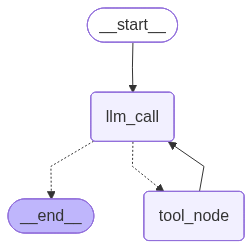

================================ Human Message =================================

Add 3 and 4.
================================== Ai Message ==================================
Tool Calls:
  add (d670abd4-ae2a-44b9-aee8-b1a171f1c0b6)
 Call ID: d670abd4-ae2a-44b9-aee8-b1a171f1c0b6
  Args:
    a: 3
    b: 4
================================= Tool Message =================================

7
================================== Ai Message ==================================

The sum of 3 and 4 is 7.


In [7]:
# Build workflow
agent_builder = StateGraph(MessagesState)

# Add nodes
agent_builder.add_node("llm_call", llm_call)
agent_builder.add_node("tool_node", tool_node)

# Add edges to connect nodes
agent_builder.add_edge(START, "llm_call")
agent_builder.add_conditional_edges(
    "llm_call",
    should_continue,
    ["tool_node", END]
)
agent_builder.add_edge("tool_node", "llm_call")

# Compile the agent
agent = agent_builder.compile()

# Show the agent
from IPython.display import Image, display
display(Image(agent.get_graph(xray=True).draw_mermaid_png()))

# Invoke
from langchain.messages import HumanMessage
messages = [HumanMessage(content="Add 3 and 4.")]
messages = agent.invoke({"messages": messages})
for m in messages["messages"]:
    m.pretty_print()

## Use the Functional API

### 1. Define tools and model
In this example, we’ll use the locally running Qwen2.5 model and define tools for addition, multiplication, and division

In [7]:
from langchain.tools import tool
from langchain_ollama import ChatOllama


model = ChatOllama(
    model="qwen2.5",
    temperature=0
)

# Define tools
@tool
def multiply(a: int, b: int) -> int:
    """Multiply `a` and `b`.

    Args:
        a: First int
        b: Second int
    """
    return a * b


@tool
def add(a: int, b: int) -> int:
    """Adds `a` and `b`.

    Args:
        a: First int
        b: Second int
    """
    return a + b


@tool
def divide(a: int, b: int) -> float:
    """Divide `a` and `b`.

    Args:
        a: First int
        b: Second int
    """
    return a / b


# Augment the LLM with tools
tools = [add, multiply, divide]
tools_by_name = {tool.name: tool for tool in tools}
model_with_tools = model.bind_tools(tools)

from langgraph.graph import add_messages
from langchain.messages import (
    SystemMessage,
    HumanMessage,
    ToolCall,
)
from langchain_core.messages import BaseMessage
from langgraph.func import entrypoint, task

### 2. Define model node
The model node is used to call the LLM and decide whether to call a tool or not.

The @task decorator marks a function as a task that can be executed as part of the agent. Tasks can be called synchronously or asynchronously within your entrypoint function.

In [8]:
@task
def call_llm(messages: list[BaseMessage]):
    """LLM decides whether to call a tool or not"""
    return model_with_tools.invoke(
        [
            SystemMessage(
                content="You are a helpful assistant tasked with performing arithmetic on a set of inputs."
            )
        ]
        + messages
    )

### 3. Define tool node
The tool node is used to call the tools and return the results.

In [9]:
@task
def call_tool(tool_call: ToolCall):
    """Performs the tool call"""
    tool = tools_by_name[tool_call["name"]]
    return tool.invoke(tool_call)

### 4. Define agent
The agent is built using the @entrypoint function.

In the Functional API, instead of defining nodes and edges explicitly, you write standard control flow logic (loops, conditionals) within a single function.

In [10]:
@entrypoint()
def agent(messages: list[BaseMessage]):
    model_response = call_llm(messages).result()

    while True:
        if not model_response.tool_calls:
            break

        # Execute tools
        tool_result_futures = [
            call_tool(tool_call) for tool_call in model_response.tool_calls
        ]
        tool_results = [fut.result() for fut in tool_result_futures]
        messages = add_messages(messages, [model_response, *tool_results])
        model_response = call_llm(messages).result()

    messages = add_messages(messages, model_response)
    return messages

# Invoke
messages = [HumanMessage(content="Add 3 and 4.")]
for chunk in agent.stream(messages, stream_mode="updates"):
    print(chunk)
    print("\n")

{'call_llm': AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen2.5', 'created_at': '2025-11-20T06:28:01.783913Z', 'done': True, 'done_reason': 'stop', 'total_duration': 516203792, 'load_duration': 50445042, 'prompt_eval_count': 344, 'prompt_eval_duration': 19300584, 'eval_count': 25, 'eval_duration': 445085375, 'logprobs': None, 'model_name': 'qwen2.5', 'model_provider': 'ollama'}, id='lc_run--e8f0f364-2d5a-4c88-b8c8-e94cd3002eb0-0', tool_calls=[{'name': 'add', 'args': {'a': 3, 'b': 4}, 'id': '5f445381-dcb0-4c84-895e-98787033cfb9', 'type': 'tool_call'}], usage_metadata={'input_tokens': 344, 'output_tokens': 25, 'total_tokens': 369})}


{'call_tool': ToolMessage(content='7', name='add', tool_call_id='5f445381-dcb0-4c84-895e-98787033cfb9')}


{'call_llm': AIMessage(content='The sum of 3 and 4 is 7.', additional_kwargs={}, response_metadata={'model': 'qwen2.5', 'created_at': '2025-11-20T06:28:02.139517Z', 'done': True, 'done_reason': 'stop', 'total_duration': 34